## 1. Load the Dataset

In [1]:
import json
import math
import os

# Load the dataset
dataset_path = os.path.join(os.getcwd(), 'text_segmentation_dataset.json')
with open(dataset_path, 'r') as f:
    dataset = json.load(f)

metadata = dataset['metadata']
word_counts = dataset['word_counts']
test_cases = dataset['test_cases']

print(f"Vocabulary size : {metadata['vocabulary_size']}")
print(f"Test case count : {metadata['test_case_count']}")
print(f"Total corpus words: {metadata['total_corpus_words']}")
print(f"\nSample vocabulary entries (first 10):")
for i, (word, count) in enumerate(list(word_counts.items())[:10]):
    print(f"  {word:>12s} -> {count}")

Vocabulary size : 1500
Test case count : 1000
Total corpus words: 735040

Sample vocabulary entries (first 10):
           the -> 69971
            of -> 36412
           and -> 28853
            to -> 26158
             a -> 23195
            in -> 21337
          that -> 10594
            is -> 10109
           was -> 9815
            he -> 9548


## 2. Compute Log Probabilities

In [2]:
# Build log-probability dictionary
total_words = metadata['total_corpus_words']
vocabulary = set(word_counts.keys())
max_word_len = max(len(w) for w in vocabulary)

# Log probability for each word: log10(count / total)
log_prob = {}
for word, count in word_counts.items():
    log_prob[word] = math.log10(count / total_words)

print(f"Number of words in vocabulary : {len(vocabulary)}")
print(f"Maximum word length            : {max_word_len}")
print(f"\nSample log-probabilities:")
for word in ['the', 'of', 'and', 'problem', 'education']:
    if word in log_prob:
        print(f"  P('{word}') = {10**log_prob[word]:.6f},  log10 P = {log_prob[word]:.4f}")

Number of words in vocabulary : 1500
Maximum word length            : 14

Sample log-probabilities:
  P('the') = 0.095193,  log10 P = -1.0214
  P('of') = 0.049537,  log10 P = -1.3051
  P('and') = 0.039254,  log10 P = -1.4061
  P('problem') = 0.000426,  log10 P = -3.3708
  P('education') = 0.000291,  log10 P = -3.5359


In [ ]:
def dp_segment(text, vocabulary, log_prob, max_word_len):
    """
    Segment `text` using Dynamic Programming to maximise total log probability.
    
    dp[i] = best (maximum) total log-probability for text[0:i]
    backtrack[i] = the starting index j of the last word in the optimal
                   segmentation of text[0:i]
    
    Returns:
      A string of space-separated words (the optimal segmentation).
    """
    n = len(text)
    
    # dp[i] = max log-prob for text[0:i]; dp[0] = 0 (empty string)
    dp = [-float('inf')] * (n + 1)
    dp[0] = 0.0
    
    # backtrack[i] = start index of the word ending at position i
    backtrack = [-1] * (n + 1)
    
    for i in range(1, n + 1):
        # Try all possible last words ending at position i
        for j in range(max(0, i - max_word_len), i):
            word = text[j:i]
            if word in vocabulary and dp[j] > -float('inf'):
                candidate = dp[j] + log_prob[word]
                if candidate > dp[i]:
                    dp[i] = candidate
                    backtrack[i] = j
    
    # If we couldn't segment the entire string, fall back to character-by-character
    if dp[n] == -float('inf'):
        # Fallback: try to segment as much as possible
        # This handles cases where some characters are not in any vocabulary word
        return _dp_segment_with_fallback(text, vocabulary, log_prob, max_word_len)
    
    # Backtrack to find the optimal segmentation
    words = []
    idx = n
    while idx > 0:
        start = backtrack[idx]
        words.append(text[start:idx])
        idx = start
    
    words.reverse()
    return ' '.join(words)


def _dp_segment_with_fallback(text, vocabulary, log_prob, max_word_len):
    """
    Fallback segmentation when the DP approach cannot fully segment the text.
    Uses a very low log-probability for unknown single characters so the DP
    can still find a complete path.
    """
    n = len(text)
    UNKNOWN_LOG_PROB = -20.0  # Very low probability for unknown characters
    
    dp = [-float('inf')] * (n + 1)
    dp[0] = 0.0
    backtrack = [-1] * (n + 1)
    
    for i in range(1, n + 1):
        # Try vocabulary words
        for j in range(max(0, i - max_word_len), i):
            word = text[j:i]
            if word in vocabulary and dp[j] > -float('inf'):
                candidate = dp[j] + log_prob[word]
                if candidate > dp[i]:
                    dp[i] = candidate
                    backtrack[i] = j
        
        # Also allow single-character fallback
        if dp[i - 1] > -float('inf'):
            candidate = dp[i - 1] + UNKNOWN_LOG_PROB
            if candidate > dp[i]:
                dp[i] = candidate
                backtrack[i] = i - 1
    
    # Backtrack
    words = []
    idx = n
    while idx > 0:
        start = backtrack[idx]
        words.append(text[start:idx])
        idx = start
    
    words.reverse()
    return ' '.join(words)


# Quick test
sample = test_cases[0]
pred = dp_segment(sample['input'], vocabulary, log_prob, max_word_len)
print(f"Input       : {sample['input']}")
print(f"Ground Truth: {sample['ground_truth']}")
print(f"Prediction  : {pred}")

Input       : itthatthecitytakestepstothisproblem
Ground Truth: it that the city take steps to this problem
Prediction  : it that the city take steps to this problem


In [4]:
def word_edit_distance(pred_words, true_words):
    """
    Compute the Levenshtein edit distance between two lists of words.
    Operations: insert, delete, substitute (each costs 1).
    """
    m, n = len(pred_words), len(true_words)
    # dp[i][j] = edit distance between pred_words[:i] and true_words[:j]
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    
    for i in range(m + 1):
        dp[i][0] = i
    for j in range(n + 1):
        dp[0][j] = j
    
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if pred_words[i - 1] == true_words[j - 1]:
                dp[i][j] = dp[i - 1][j - 1]
            else:
                dp[i][j] = 1 + min(
                    dp[i - 1][j],      # deletion
                    dp[i][j - 1],      # insertion
                    dp[i - 1][j - 1]   # substitution
                )
    
    return dp[m][n]

## 5. Run DP Segmentation on All Test Cases

In [5]:
exact_matches = 0
total_edit_distance = 0
results = []

for idx, tc in enumerate(test_cases):
    input_text = tc['input']
    ground_truth = tc['ground_truth']
    
    prediction = dp_segment(input_text, vocabulary, log_prob, max_word_len)
    
    pred_words = prediction.split()
    true_words = ground_truth.split()
    
    is_correct = (prediction == ground_truth)
    ed = word_edit_distance(pred_words, true_words)
    
    exact_matches += int(is_correct)
    total_edit_distance += ed
    
    results.append({
        'index': idx,
        'input': input_text,
        'ground_truth': ground_truth,
        'prediction': prediction,
        'correct': is_correct,
        'edit_distance': ed
    })
    
    # Progress indicator
    if (idx + 1) % 200 == 0:
        print(f"  Processed {idx + 1}/{len(test_cases)} test cases...")

total = len(test_cases)
accuracy = exact_matches / total
avg_edit_distance = total_edit_distance / total

print("\n" + "=" * 60)
print("   DYNAMIC PROGRAMMING SEGMENTATION RESULTS")
print("=" * 60)
print(f"  Total test cases   : {total}")
print(f"  Exact matches      : {exact_matches}")
print(f"  Accuracy           : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"  Total edit distance: {total_edit_distance}")
print(f"  Avg edit distance  : {avg_edit_distance:.4f}")
print("=" * 60)

  Processed 200/1000 test cases...
  Processed 400/1000 test cases...
  Processed 600/1000 test cases...
  Processed 800/1000 test cases...
  Processed 1000/1000 test cases...

   DYNAMIC PROGRAMMING SEGMENTATION RESULTS
  Total test cases   : 1000
  Exact matches      : 982
  Accuracy           : 0.9820 (98.20%)
  Total edit distance: 37
  Avg edit distance  : 0.0370


## 5.1 Segmented Output for All Test Cases

In [6]:
# Print segmented output for all test cases
print('=' * 80)
print('   SEGMENTED OUTPUT — DYNAMIC PROGRAMMING — ALL TEST CASES')
print('=' * 80)
for r in results:
    status = 'CORRECT' if r['correct'] else 'WRONG'
    print(f"\n[{status}] Test Case {r['index'] + 1}")
    print(f"  Input       : {r['input']}")
    print(f"  Ground Truth: {r['ground_truth']}")
    print(f"  Prediction  : {r['prediction']}")
    if not r['correct']:
        print(f"  Edit Dist.  : {r['edit_distance']}")
print('\n' + '=' * 80)
correct_count = sum(1 for r in results if r['correct'])
incorrect_count = sum(1 for r in results if not r['correct'])
print(f'Total: {len(results)} test cases | Correct: {correct_count} | Incorrect: {incorrect_count}')
print('=' * 80)


   SEGMENTED OUTPUT — DYNAMIC PROGRAMMING — ALL TEST CASES

[CORRECT] Test Case 1
  Input       : itthatthecitytakestepstothisproblem
  Ground Truth: it that the city take steps to this problem
  Prediction  : it that the city take steps to this problem

[CORRECT] Test Case 2
  Input       : oftitlelawwasalsobythe
  Ground Truth: of title law was also by the
  Prediction  : of title law was also by the

[CORRECT] Test Case 3
  Input       : failuretodothiswillcontinuetoplaceaon
  Ground Truth: failure to do this will continue to place a on
  Prediction  : failure to do this will continue to place a on

[CORRECT] Test Case 4
  Input       : onotherthethat
  Ground Truth: on other the that
  Prediction  : on other the that

[CORRECT] Test Case 5
  Input       : williamforfromhiswifeincourt
  Ground Truth: william for from his wife in court
  Prediction  : william for from his wife in court

[CORRECT] Test Case 6
  Input       : thecouplewasmarried
  Ground Truth: the couple was married
 

## 6. Detailed Analysis

In [7]:
# Show some correctly segmented examples
correct_examples = [r for r in results if r['correct']]
print(f"\n--- Correctly Segmented Examples (showing up to 5) ---\n")
for r in correct_examples[:5]:
    print(f"  Input : {r['input']}")
    print(f"  Output: {r['prediction']}")
    print()


--- Correctly Segmented Examples (showing up to 5) ---

  Input : itthatthecitytakestepstothisproblem
  Output: it that the city take steps to this problem

  Input : oftitlelawwasalsobythe
  Output: of title law was also by the

  Input : failuretodothiswillcontinuetoplaceaon
  Output: failure to do this will continue to place a on

  Input : onotherthethat
  Output: on other the that

  Input : williamforfromhiswifeincourt
  Output: william for from his wife in court



In [8]:
# Show some incorrectly segmented examples
incorrect_examples = [r for r in results if not r['correct']]
print(f"\n--- Incorrectly Segmented Examples (showing up to 10) ---\n")
for r in incorrect_examples[:10]:
    print(f"  Input       : {r['input']}")
    print(f"  Ground Truth: {r['ground_truth']}")
    print(f"  Prediction  : {r['prediction']}")
    print(f"  Edit Distance: {r['edit_distance']}")
    print()


--- Incorrectly Segmented Examples (showing up to 10) ---

  Input       : theyhaveasonwilliamandadaughterof
  Ground Truth: they have a son william and a daughter of
  Prediction  : they have as on william and a daughter of
  Edit Distance: 2

  Input       : themaybehighlytomytoldthecourt
  Ground Truth: the may be highly to my told the court
  Prediction  : the maybe highly to my told the court
  Edit Distance: 2

  Input       : afterthisithinkweshouldcertainlyfollowthroughonithe
  Ground Truth: after this i think we should certainly follow through on it he
  Prediction  : after this i think we should certainly follow through on i the
  Edit Distance: 2

  Input       : butfromanonecanapproachit
  Ground Truth: but from a none can approach it
  Prediction  : but from an one can approach it
  Edit Distance: 2

  Input       : thenalongtoleftcentertoboth
  Ground Truth: then a long to left center to both
  Prediction  : then along to left center to both
  Edit Distance: 2

  Input  

In [9]:
# Distribution of edit distances
from collections import Counter

ed_dist = Counter(r['edit_distance'] for r in results)
print("\n--- Edit Distance Distribution ---\n")
print(f"  {'Edit Distance':<15} {'Count':<10} {'Percentage':<10}")
print(f"  {'-'*35}")
for ed_val in sorted(ed_dist.keys()):
    count = ed_dist[ed_val]
    pct = count / total * 100
    print(f"  {ed_val:<15} {count:<10} {pct:.1f}%")


--- Edit Distance Distribution ---

  Edit Distance   Count      Percentage
  -----------------------------------
  0               982        98.2%
  2               17         1.7%
  3               1          0.1%


## 7. Visualization

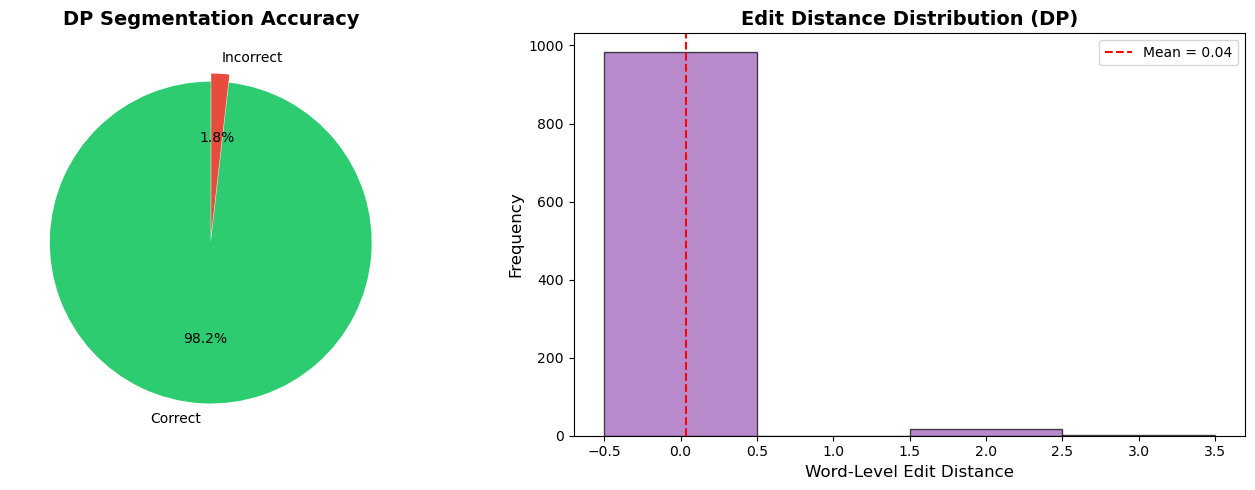

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Accuracy pie chart
axes[0].pie(
    [exact_matches, total - exact_matches],
    labels=['Correct', 'Incorrect'],
    autopct='%1.1f%%',
    colors=['#2ecc71', '#e74c3c'],
    startangle=90,
    explode=(0.05, 0)
)
axes[0].set_title('DP Segmentation Accuracy', fontsize=14, fontweight='bold')

# Plot 2: Edit distance histogram
edit_distances = [r['edit_distance'] for r in results]
axes[1].hist(edit_distances, bins=range(0, max(edit_distances) + 2),
             color='#9b59b6', edgecolor='black', alpha=0.7, align='left')
axes[1].set_xlabel('Word-Level Edit Distance', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].set_title('Edit Distance Distribution (DP)', fontsize=14, fontweight='bold')
axes[1].axvline(x=avg_edit_distance, color='red', linestyle='--', label=f'Mean = {avg_edit_distance:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()